⏳ Loading filtered tiles from GeoPackage...
⏳ Loading full GeoPackage for global map display...
⏳ Loading auxiliary datasets (SSH & mangroves)...
⏳ Computing Panel D gain/loss distance profiles for tile C (N18W078)...
⏳ Compiling Figure 1 layout with map + b, c, d insets...
🎉 Success! Figure 1 compiled and saved at: D:\MANGROVES\Research_Article_Clean\Figure1\Figure1.tif


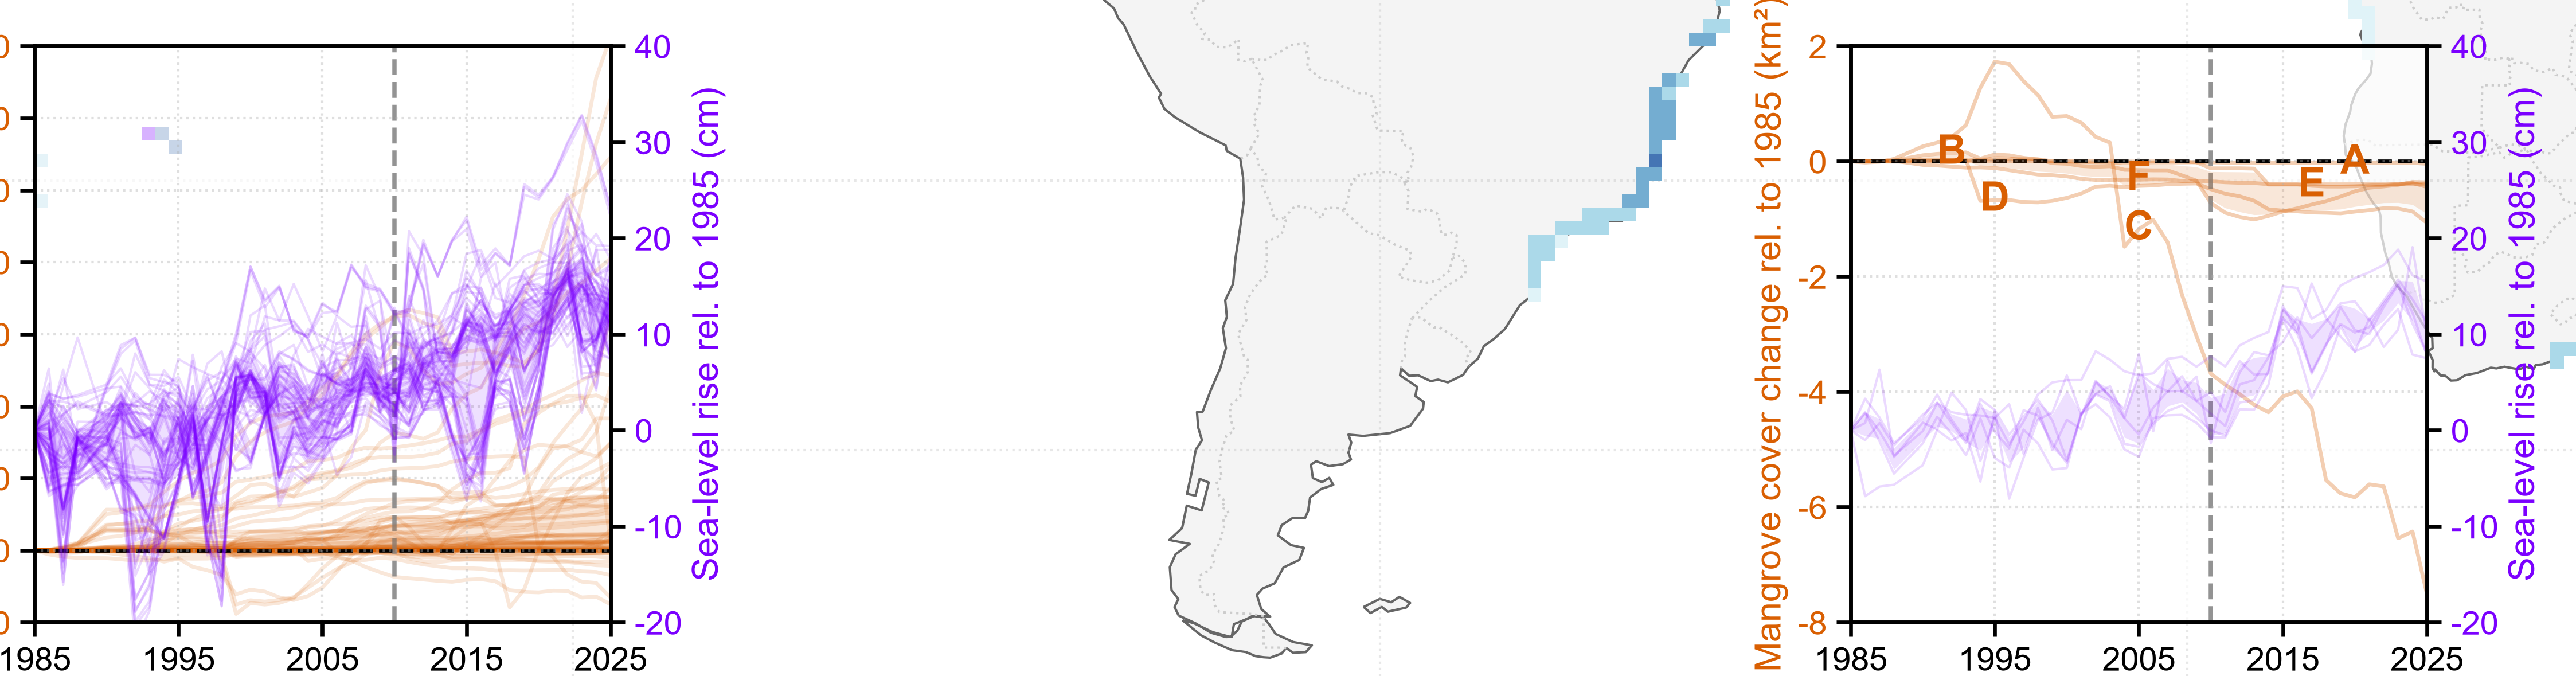

In [32]:
"""
================================================================================
SCRIPT NAME: Figure 1

AUTHOR: R. Walcker
================================================================================
"""

import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import warnings
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LatitudeFormatter, LongitudeFormatter
import geopandas as gpd
from matplotlib.colors import ListedColormap
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import rasterio
from rasterio.warp import Resampling, reproject
from scipy.ndimage import distance_transform_edt
from scipy.stats import linregress
import seaborn as sns

# ==========================================
# STEP 0: DIRECTORY SETUP & TYPOGRAPHY
# ==========================================
OUT_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Figure1")
OUT_GPKG_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Figure1")
OUT_DIR.mkdir(parents=True, exist_ok=True)
OUT_GPKG_DIR.mkdir(parents=True, exist_ok=True)

# Clean environment paths
YEARLY_STATS_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\Distance_CSVs")
CSV_MSL_PATH = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\ecmwf_msl_annual_1deg_tiles.csv")
CSV_MANGROVES = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\gmwv4_surfaces_annual_1deg_tiles.csv")

# Gain / loss age rasters and GSW baseline for Panel D
GAIN_AGE_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\Mangrove_Age_2025_Rasters")
LOSS_AGE_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\Loss_Age_2025_Rasters")
GSW_BASELINE_DIR = Path(r"D:\MANGROVES\Research_Article_Clean\Created_Data\GSW_1984_baseline")

# Set global publication typography standards (Nature Journal guidelines)
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "dejavusans",
    "axes.linewidth": 0.8,
    "font.size": 9.0,
    "axes.labelsize": 9.0,
    "axes.titlesize": 10.0,
    "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0,
})

GPKG_FILTERED_PATH = OUT_GPKG_DIR / "mangrove_rates_and_percentages_filtered.gpkg"
GPKG_FULL_PATH = OUT_GPKG_DIR / "mangrove_rates_and_percentages.gpkg"

if not GPKG_FILTERED_PATH.exists():
    raise FileNotFoundError(f"⚠️ Filtered GeoPackage not found: {GPKG_FILTERED_PATH}.")

print("⏳ Loading filtered tiles from GeoPackage...")
gdf_filtered = gpd.read_file(GPKG_FILTERED_PATH)

# Full (unfiltered / pristine) GeoPackage for global map display (Panel A)
print("⏳ Loading full GeoPackage for global map display...")
gdf_map_global = gpd.read_file(GPKG_FULL_PATH) if GPKG_FULL_PATH.exists() else gdf_filtered

# Load and pivot SSH and mangrove datasets
print("⏳ Loading auxiliary datasets (SSH & mangroves)...")
df_msl_raw = pd.read_csv(CSV_MSL_PATH, sep=";")
if len(df_msl_raw.columns) == 1:
    df_msl_raw = pd.read_csv(CSV_MSL_PATH, sep=",")

df_msl_raw["tile_id"] = df_msl_raw["tile_id"].astype(str).str.strip()
df_msl_raw["year"] = df_msl_raw["year"].astype(int)

df_msl_data = df_msl_raw.pivot(index="year", columns="tile_id", values="SSH_m")
df_msl_data.index = df_msl_data.index.astype(int)
df_msl_data.sort_index(ascending=True, inplace=True)
df_msl_data.columns = df_msl_data.columns.astype(str).str.strip()

df_mng_raw = pd.read_csv(CSV_MANGROVES, sep=";")
if len(df_mng_raw.columns) == 1:
    df_mng_raw = pd.read_csv(CSV_MANGROVES, sep=",")
df_mng_raw["tile_id"] = df_mng_raw["tile_id"].astype(str).str.strip()
df_mng_raw["year"] = df_mng_raw["year"].astype(int)
pivot_mng = df_mng_raw.pivot(index="year", columns="tile_id", values="area_km2")
pivot_mng.columns = pivot_mng.columns.astype(str).str.strip()

possible_cols = ["tile_id", "clean_id", "id", "TILE_ID"]
col_filtered_tile = next((c for c in possible_cols if c in gdf_filtered.columns), gdf_filtered.columns[0])

filtered_tiles = gdf_filtered[col_filtered_tile].astype(str).str.strip().tolist()
num_selected_tiles = len(filtered_tiles)

years_common = [y for y in range(1985, 2026) if y in df_msl_data.index and y in pivot_mng.index]


# ==========================================
# COLOR PALETTE CONFIGURATION
# ==========================================
COLOR_MANGROVE = "#d95f02"
COLOR_SSH_MEAN = "#7b00ff"

target_years = [1985, 1995, 2005, 2015, 2025]
palette_green = sns.color_palette("YlGn", len(target_years))

slr_bins = [0.0, 3.0, 4.0, 5.0, 6.0, np.inf]
slr_colors = ["#e0f3f8", "#abd9e9", "#74add1", "#4575b4", "#7b00ff"]

def get_slr_color(rate):
    if pd.isna(rate):
        return "#999999"
    for i in range(len(slr_bins) - 1):
        if slr_bins[i] <= rate < slr_bins[i+1]:
            return slr_colors[i]
    return slr_colors[-1]

possible_cols_slr = ["tile_id", "clean_id", "id", "TILE_ID"]
col_slr_tile = next((c for c in possible_cols_slr if c in gdf_filtered.columns), gdf_filtered.columns[0])
tile_to_slr = {}
if 'SLR_rate_2010-2025' in gdf_filtered.columns:
    for _, row in gdf_filtered.iterrows():
        t_id = str(row[col_slr_tile]).strip()
        tile_to_slr[t_id] = row["SLR_rate_2010-2025"]


# ==========================================
# STEP 1: DATA NORMALIZATION & TIME-SERIES AGGREGATION
# ==========================================
valid_mng = [t for t in filtered_tiles if t in pivot_mng.columns]
valid_ssh = [t for t in filtered_tiles if t in df_msl_data.index.astype(str) or t in df_msl_data.columns]

df_zone_mng = pivot_mng.loc[years_common, valid_mng] if valid_mng else pd.DataFrame()
norm_dict, pct_dict = {}, {}
for col in df_zone_mng.columns:
    sc = df_zone_mng[col]
    b1985 = sc.loc[1985] if 1985 in sc.index else (sc.dropna().iloc[0] if not sc.dropna().empty else np.nan)
    if pd.notna(b1985) and b1985 >= 0.10:
        diff_sc = sc - b1985
        norm_dict[col] = diff_sc
        pct_dict[col] = (diff_sc / b1985) * 100.0

df_norm_mng = pd.DataFrame(norm_dict, index=df_zone_mng.index)
df_pct_mng = pd.DataFrame(pct_dict, index=df_zone_mng.index)
df_norm_mng_raw = df_norm_mng

df_ssh = df_msl_data.loc[years_common, valid_ssh] * 100.0 if valid_ssh else pd.DataFrame()
ssh_norm_dict = {}
for col in df_ssh.columns:
    bval_1985 = df_ssh.loc[1985, col] if 1985 in df_ssh.index else (df_ssh[col].dropna().iloc[0] if not df_ssh[col].dropna().empty else np.nan)
    ssh_norm_dict[col] = df_ssh[col] - bval_1985
df_ssh = pd.DataFrame(ssh_norm_dict, index=df_ssh.index)
df_ssh_raw = df_ssh


# ==========================================
# STEP 2: EXTRACT PERSISTENTLY DECLINING SUBSET & EXPORT
# ==========================================
df_pct_mng_2010 = df_pct_mng.loc[2010:2025] if 2010 in df_pct_mng.index else df_pct_mng.loc[df_pct_mng.index >= 2010]
declining_mask = (df_pct_mng_2010 < -5.0).all(axis=0)
declining_tile_ids = declining_mask[declining_mask].index.tolist()
num_declining_tiles = len(declining_tile_ids)

df_norm_mng_dec = df_norm_mng[[c for c in declining_tile_ids if c in df_norm_mng.columns]]
df_norm_mng_dec_raw = df_norm_mng_raw[[c for c in declining_tile_ids if c in df_norm_mng_raw.columns]]

declining_columns_list = df_norm_mng_dec_raw.columns.tolist() if not df_norm_mng_dec_raw.empty else []
alphabet_labels = [chr(65 + i) for i in range(len(declining_columns_list))]
tile_to_letter = {tile_id: alphabet_labels[i] for i, tile_id in enumerate(declining_columns_list)}
letter_to_tile = {letter: tile_id for tile_id, letter in tile_to_letter.items()}

# Select only tile "C" from Panel C for Panel D
panel_d_tile_id = letter_to_tile.get("C", declining_columns_list[2] if len(declining_columns_list) > 2 else (declining_columns_list[0] if declining_columns_list else None))

declining_ssh_cols = [t for t in declining_tile_ids if t in df_ssh.columns]
df_ssh_dec_raw = df_ssh_raw[declining_ssh_cols] if declining_ssh_cols else pd.DataFrame()

gdf_declining = gdf_filtered[gdf_filtered[col_filtered_tile].astype(str).str.strip().isin(declining_tile_ids)].copy()
output_declining_gpkg = OUT_GPKG_DIR / "mangrove_declining_tiles_strict.gpkg"
if gdf_declining.crs is not None and gdf_declining.crs.to_string() != "EPSG:4326":
    gdf_declining = gdf_declining.to_crs(epsg=4326)
gdf_declining.to_file(output_declining_gpkg, driver="GPKG")


# ==========================================
# STEP 2.BIS: CROSS-SHORE GAIN & LOSS PROFILES FOR PANEL D (TILE C ONLY)
# ==========================================
REF_YEAR = 2025
EXCLUDE_GAIN_AGE = 41   # Exclude persistent mangrove (age 41) for gains only; keep for losses
AGE_BIN_SIZE = 5        # 5-year intervals (using 2020-2025 for the most recent period)

GSW_WATER_VALUE = 1
MAX_SEA_DIST = 20000.0  # m (seaward side -> negative)
MAX_LAND_DIST = 5000.0  # m (landward side -> positive)
DIST_BIN_SIZE = 100.0   # m
PIXEL_AREA_KM2 = (29.869 ** 2) / 1e6

dist_edges = np.arange(-MAX_SEA_DIST, MAX_LAND_DIST + DIST_BIN_SIZE, DIST_BIN_SIZE)
dist_centers = (dist_edges[:-1] + dist_edges[1:]) / 2.0
n_bins = len(dist_centers)

gain_area_by_period = {}
loss_area_by_period = {}

def _find_tile_raster(directory: Path, prefixes: list[str], tile_id: str) -> Path | None:
    for pref in prefixes:
        candidate = directory / f"{pref}{tile_id}.tif"
        if candidate.exists():
            return candidate
    matches = sorted(directory.glob(f"*{tile_id}*.tif"))
    return matches[0] if matches else None

def _find_gsw_baseline(directory: Path, tile_id: str) -> Path | None:
    matches = sorted(directory.glob(f"*JRC_Yearly_{tile_id}_baseline_water*.tif"))
    if matches:
        return matches[0]
    matches = sorted(directory.glob(f"*{tile_id}*baseline_water*.tif"))
    return matches[0] if matches else None

if panel_d_tile_id is not None:
    print(f"⏳ Computing Panel D gain/loss distance profiles for tile C ({panel_d_tile_id})...")
    gain_path = _find_tile_raster(
        GAIN_AGE_DIR,
        ["mangrove_age_2025_", "gain_age_2025_"],
        panel_d_tile_id,
    )
    loss_path = _find_tile_raster(
        LOSS_AGE_DIR,
        ["loss_age_2025_"],
        panel_d_tile_id,
    )
    gsw_path = _find_gsw_baseline(GSW_BASELINE_DIR, panel_d_tile_id)

    if (gain_path is not None or loss_path is not None) and gsw_path is not None:
        ref_path = gain_path if gain_path is not None else loss_path
        with rasterio.open(ref_path) as ref_src:
            ref_shape = (ref_src.height, ref_src.width)
            ref_crs = ref_src.crs
            ref_transform = ref_src.transform
            px_w = abs(ref_transform.a)
            px_h = abs(ref_transform.e)

        px_area_tile = (px_w * px_h) / 1e6 if (px_w > 0 and px_h > 0) else PIXEL_AREA_KM2

        with rasterio.open(gsw_path) as gsw_src:
            gsw_aligned = np.zeros(ref_shape, dtype=np.float32)
            reproject(
                source=rasterio.band(gsw_src, 1),
                destination=gsw_aligned,
                src_transform=gsw_src.transform,
                src_crs=gsw_src.crs,
                src_nodata=gsw_src.nodata,
                dst_transform=ref_transform,
                dst_crs=ref_crs,
                dst_nodata=0,
                resampling=Resampling.nearest,
            )

        is_water = gsw_aligned == GSW_WATER_VALUE
        is_land = ~is_water
        del gsw_aligned

        if np.any(is_water) and np.any(is_land):
            dist_to_land_m = distance_transform_edt(~is_land, sampling=(px_h, px_w))
            dist_to_sea_m = distance_transform_edt(~is_water, sampling=(px_h, px_w))
            signed_dist_m = np.where(is_land, dist_to_sea_m, -dist_to_land_m)
        elif np.any(is_land):
            signed_dist_m = distance_transform_edt(~is_land, sampling=(px_h, px_w))
        else:
            signed_dist_m = -distance_transform_edt(~is_water, sampling=(px_h, px_w))

        del is_water, is_land
        in_dist_range = (
            np.isfinite(signed_dist_m)
            & (signed_dist_m >= -MAX_SEA_DIST)
            & (signed_dist_m <= MAX_LAND_DIST)
        )

        # --- GAINS (exclude age 41, 5-year periods with 2020-2025) ---
        if gain_path is not None:
            with rasterio.open(gain_path) as gain_src:
                gain_arr = gain_src.read(1)
                gain_nodata = gain_src.nodata

            valid_gain = (
                np.isfinite(gain_arr)
                & (gain_arr >= 0)
                & (gain_arr != EXCLUDE_GAIN_AGE)
                & in_dist_range
            )
            if gain_nodata is not None:
                valid_gain &= gain_arr != gain_nodata

            if np.any(valid_gain):
                gain_age_clean = gain_arr[valid_gain].astype(int)
                gain_dist_clean = signed_dist_m[valid_gain]
                gain_yr_start = np.where(
                    gain_age_clean <= AGE_BIN_SIZE,
                    2020,
                    REF_YEAR - (((gain_age_clean - 1) // AGE_BIN_SIZE) * AGE_BIN_SIZE + AGE_BIN_SIZE),
                )
                gain_yr_end = np.where(
                    gain_yr_start == 2020,
                    REF_YEAR,
                    gain_yr_start + AGE_BIN_SIZE - 1,
                )
                gain_period_arr = np.array([f"{ys}-{ye}" for ys, ye in zip(gain_yr_start, gain_yr_end)], dtype=object)
                for per_label in np.unique(gain_period_arr):
                    dists_p = gain_dist_clean[gain_period_arr == per_label]
                    weights_p = np.full(len(dists_p), px_area_tile, dtype=float)
                    area_bins, _ = np.histogram(dists_p, bins=dist_edges, weights=weights_p)
                    gain_area_by_period[per_label] = area_bins
            del gain_arr, valid_gain

        # --- LOSSES (include age 41, 5-year periods with 2020-2025) ---
        if loss_path is not None:
            with rasterio.open(loss_path) as loss_src:
                loss_arr = loss_src.read(1)
                loss_nodata = loss_src.nodata

            valid_loss = np.isfinite(loss_arr) & (loss_arr >= 0) & in_dist_range
            if loss_nodata is not None:
                valid_loss &= loss_arr != loss_nodata

            if np.any(valid_loss):
                loss_age_clean = loss_arr[valid_loss].astype(int)
                loss_dist_clean = signed_dist_m[valid_loss]
                loss_yr_start = np.where(
                    loss_age_clean <= AGE_BIN_SIZE,
                    2020,
                    REF_YEAR - (((loss_age_clean - 1) // AGE_BIN_SIZE) * AGE_BIN_SIZE + AGE_BIN_SIZE),
                )
                loss_yr_end = np.where(
                    loss_yr_start == 2020,
                    REF_YEAR,
                    loss_yr_start + AGE_BIN_SIZE - 1,
                )
                loss_period_arr = np.array([f"{ys}-{ye}" for ys, ye in zip(loss_yr_start, loss_yr_end)], dtype=object)
                for per_label in np.unique(loss_period_arr):
                    dists_p = loss_dist_clean[loss_period_arr == per_label]
                    weights_p = np.full(len(dists_p), -px_area_tile, dtype=float)
                    area_bins, _ = np.histogram(dists_p, bins=dist_edges, weights=weights_p)
                    loss_area_by_period[per_label] = area_bins
            del loss_arr, valid_loss

        del signed_dist_m, in_dist_range

gain_period_labels = sorted(gain_area_by_period.keys(), key=lambda s: int(s.split("-")[0]))
loss_period_labels = sorted(loss_area_by_period.keys(), key=lambda s: int(s.split("-")[0]))

# "viridis": dark purple/blue for older periods -> yellow for more recent periods
gain_palette = sns.color_palette("viridis", max(len(gain_period_labels), 1))
gain_period_to_color = {lbl: gain_palette[i] for i, lbl in enumerate(gain_period_labels)}

# "rocket": light tones for older periods -> dark tones for more recent periods (inverted vs "rocket_r")
loss_palette = sns.color_palette("rocket", max(len(loss_period_labels), 1))
loss_period_to_color = {lbl: loss_palette[i] for i, lbl in enumerate(loss_period_labels)}


# ==========================================
# STEP 3: FIGURE COMPILATION (MAP WITH B, C, D INSETS)
# ==========================================
print("⏳ Compiling Figure 1 layout with map + b, c, d insets...")
plt.close('all')

# --- USER-EDITABLE INSET & LEGEND COORDINATES (lon in [-180, 180], lat in [-60, 60]) ---
# Top-left corner of each square inset:
INSET_B_TOP_LON, INSET_B_TOP_LAT = -160.0, -10.0
INSET_C_TOP_LON, INSET_C_TOP_LAT = -25.0, -10.0
INSET_D_TOP_LON, INSET_D_TOP_LAT = 72.0, -10.0

# Square inset sizes (fraction of map axes width):
INSET_B_SIZE = 0.3564
INSET_C_SIZE = 0.3564
INSET_D_SIZE = 0.3240

# Translucent white fill on the inset axis frame itself (under the curves)
INSET_BC_BG_ALPHA = 0.70

# --- USER-EDITABLE INSET & LEGEND COORDINATES (lon in [-180, 180], lat in [-60, 60]) ---
LEG_D_LON, LEG_D_LAT = 140.0, 20.0  # point bas-gauche de l'ensemble (Gain en bas, Loss au-dessus)
LEG_D_LOSS_DY_FRAC = 0.14  # décalage vertical entre les deux légendes (à ajuster selon vos périodes)
# --------------------------------------------------------------------------------------

fig = plt.figure(figsize=(16.0, 9.0), facecolor="white", dpi=600)

# Map extent in PlateCarree
MAP_LON_MIN, MAP_LON_MAX = -180.0, 180.0
MAP_LAT_MIN, MAP_LAT_MAX = -60.0, 60.0
MAP_RECT = [0.06, 0.08, 0.88, 0.84]

def lonlat_to_axes(lon: float, lat: float) -> tuple[float, float]:
    x_ax = (lon - MAP_LON_MIN) / (MAP_LON_MAX - MAP_LON_MIN)
    y_ax = (lat - MAP_LAT_MIN) / (MAP_LAT_MAX - MAP_LAT_MIN)
    return x_ax, y_ax

def add_geo_square_inset_top_left(parent_ax, top_lon: float, top_lat: float, box_size_frac: float, bg_alpha: float | None = None):
    """Create a square inset axis (box_aspect=1) anchored at its top-left corner (top_lon, top_lat)."""
    x_top, y_top = lonlat_to_axes(top_lon, top_lat)
    x0 = x_top
    y0 = y_top - box_size_frac
    ax_ins = parent_ax.inset_axes([x0, y0, box_size_frac, box_size_frac], transform=parent_ax.transAxes, zorder=10.0)
    ax_ins.set_box_aspect(1)
    ax_ins.set_anchor("NW")
    if bg_alpha is not None:
        ax_ins.set_facecolor("white")
        ax_ins.patch.set_alpha(bg_alpha)
        ax_ins.patch.set_visible(True)
        ax_ins.patch.set_zorder(0.2)
    else:
        ax_ins.set_facecolor("white")
        ax_ins.patch.set_alpha(0.95)
    return ax_ins


# ------------------------------------------
# PANEL A: GLOBAL MAP
# ------------------------------------------
ax_map = fig.add_axes(MAP_RECT, projection=ccrs.PlateCarree())
ax_map.add_feature(cfeature.LAND, facecolor="#f4f4f4", zorder=1)
ax_map.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor="#666666", zorder=2)
ax_map.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, edgecolor="#cccccc", zorder=2)

max_slr_val = np.nanmax(gdf_map_global["SLR_rate_2010-2025"])
upper_bin = max(6.0, float(max_slr_val)) if np.isfinite(max_slr_val) else 7.0
bins = [0.0, 3.0, 4.0, 5.0, 6.0, upper_bin]
map_labels = [
    "<3 mm/yr (Low)",
    "3-4 mm/yr (Moderate)",
    "4-5 mm/yr (High)",
    "5-6 mm/yr (Very High)",
    ">6 mm/yr (Critical)",
]
gdf_map_global["slr_class"] = pd.cut(
    gdf_map_global["SLR_rate_2010-2025"],
    bins=bins,
    labels=map_labels,
    include_lowest=True,
)
discrete_cmap = ListedColormap(slr_colors)

gdf_map_global.plot(
    column="slr_class",
    ax=ax_map,
    cmap=discrete_cmap,
    edgecolor="none",
    transform=ccrs.PlateCarree(),
    zorder=3,
)

if not gdf_declining.empty:
  default_offsets = {
      "A": (-40, 0),
      "B": (0, 35),
      "C": (35, -25),
      "D": (-35, -30),
      "E": (0, -35),
      "F": (-30, 25),
  }

  for idx, row in gdf_declining.iterrows():
    t_id = str(row[col_filtered_tile]).strip()
    if t_id in tile_to_letter:
      letter = tile_to_letter[t_id]
      centroid = row.geometry.centroid
      lon, lat = centroid.x, centroid.y
      dx, dy = default_offsets.get(letter, (25, 25))

      ax_map.annotate(
          letter,
          xy=(lon, lat),
          xytext=(dx, dy),
          textcoords="offset points",
          transform=ccrs.PlateCarree(),
          fontsize=10.5,
          fontweight="bold",
          color="black",
          ha="center",
          va="center",
          arrowprops=dict(
              arrowstyle="-|>",
              lw=0.7,
              color="black",
              mutation_scale=8,
              shrinkA=0,
              shrinkB=0,
          ),
          zorder=4,
      )

ax_map.set_extent(
    [MAP_LON_MIN, MAP_LON_MAX, MAP_LAT_MIN, MAP_LAT_MAX],
    crs=ccrs.PlateCarree(),
)

# Attach legend to fig to avoid Cartopy GeoAxes / inset z-order & transform quirks
legend_patches = [
    mpatches.Patch(color=slr_colors[i], label=map_labels[i])
    for i in range(len(map_labels))
]
leg_x = MAP_RECT[0] + 0.01 * MAP_RECT[2]
leg_y = MAP_RECT[1] + 0.65 * MAP_RECT[3]

legend = fig.legend(
    handles=legend_patches,
    title="Sea-level rise rates",
    loc="lower left",
    bbox_to_anchor=(leg_x, leg_y),
    bbox_transform=fig.transFigure,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
    edgecolor="#888888",
    fontsize=8.0,
    handlelength=0.8,
    handleheight=0.8,
    borderaxespad=0.5,
    ncol=1,
)
legend.get_frame().set_linewidth(0.6)
legend.set_zorder(100)
legend.set_in_layout(False)

valid_rates_pristine = gdf_map_global["SLR_rate_2010-2025"].dropna()
mean_rate = valid_rates_pristine.mean()
std_rate = valid_rates_pristine.std()
max_rate = valid_rates_pristine.max()
p75_rate = np.percentile(valid_rates_pristine, 75)

text_box_content = (
    f"Sea level rise (2010-2025, pristine mangrove areas) | Mean: {mean_rate:.2f}"
    f" ± {std_rate:.2f} mm/yr  |  Max: {max_rate:.2f} mm/yr  |  Top 25%:"
    f" {p75_rate:.2f} mm/yr"
)
ax_map.text(
    0.0,
    1.02,
    text_box_content,
    transform=ax_map.transAxes,
    fontsize=9.0,
    horizontalalignment="left",
    verticalalignment="bottom",
    zorder=5,
)
ax_map.text(
    -0.02,
    1.0,
    "a",
    transform=ax_map.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="right",
)

# Dotted graticule lines + labels via gridlines (avoids "Geodetic ... [degree]" axis labels)
gl = ax_map.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    xlocs=[-180, -120, -60, 0, 60, 120, 180],
    ylocs=[-40, -20, 0, 20, 40],
    linestyle=":",
    alpha=0.3,
    linewidth=0.5,
    zorder=2.5,
)
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlabel_style = {"size": 8.0}
gl.ylabel_style = {"size": 8.0}
# ------------------------------------------
# INSET B: TOP-LEFT AT INSET_B_TOP_LON, INSET_B_TOP_LAT
# ------------------------------------------
ax_b = add_geo_square_inset_top_left(ax_map, top_lon=INSET_B_TOP_LON, top_lat=INSET_B_TOP_LAT, box_size_frac=INSET_B_SIZE, bg_alpha=INSET_BC_BG_ALPHA)
ax_b.axhline(0, color="black", linestyle="--", linewidth=0.8, zorder=1.1)
ax_b.axvline(2010, color="grey", linestyle="--", linewidth=0.9, alpha=0.85, zorder=1.2)

if not df_norm_mng_raw.empty:
    df_norm_mng_raw.plot(ax=ax_b, color=COLOR_MANGROVE, alpha=0.15, linewidth=0.8, legend=False, zorder=1)

    mng_med_b = df_norm_mng_raw.median(axis=1).dropna()
    mng_p25_b = df_norm_mng_raw.quantile(0.25, axis=1).loc[mng_med_b.index]
    mng_p75_b = df_norm_mng_raw.quantile(0.75, axis=1).loc[mng_med_b.index]

    ax_b.fill_between(
        mng_med_b.index, mng_p25_b, mng_p75_b,
        color=COLOR_MANGROVE, alpha=0.15, linewidth=0, zorder=1.5
    )
    #ax_b.plot(mng_med_b.index, mng_med_b.values, color=COLOR_MANGROVE, marker="s", linewidth=1.5, markersize=2.5, label="Median mangrove change", zorder=2)

ax_b.set_xlim(1985, 2025)
ax_b.set_ylim(-10, 70)
ax_b.set_ylabel("Mangrove cover change rel. to 1985 (km²)", color=COLOR_MANGROVE, fontsize=7.5, labelpad=2)
ax_b.set_xlabel("")
ax_b.tick_params(axis="y", labelcolor=COLOR_MANGROVE, length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_b.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax_b.set_xticks(target_years)
ax_b.tick_params(axis="x", length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_b.grid(True, linestyle=":", alpha=0.4, linewidth=0.5)

ax_b_right = ax_b.twinx()
ax_b_right.set_facecolor("none")
ax_b_right.patch.set_alpha(0.0)
ax_b_right.patch.set_visible(False)
if not df_ssh_raw.empty:
    for col in df_ssh_raw.columns:
        rate = tile_to_slr.get(col, np.nan)
        col_color = get_slr_color(rate)
        rgba_color = mcolors.to_rgba(col_color, alpha=0.15)
        series = df_ssh_raw[col].dropna()
        if not series.empty:
            ax_b_right.plot(series.index, series.values, color=rgba_color, linewidth=0.5, zorder=1)

    ssh_med_b = df_ssh_raw.median(axis=1).dropna()
    ssh_p25_b = df_ssh_raw.quantile(0.25, axis=1).loc[ssh_med_b.index]
    ssh_p75_b = df_ssh_raw.quantile(0.75, axis=1).loc[ssh_med_b.index]

    ax_b_right.fill_between(
        ssh_med_b.index, ssh_p25_b, ssh_p75_b,
        color=COLOR_SSH_MEAN, alpha=0.12, linewidth=0, zorder=1.5
    )
    #ax_b_right.plot(ssh_med_b.index, ssh_med_b.values, color=COLOR_SSH_MEAN, marker="o", linestyle="--", linewidth=1.5, markersize=2.5, label="Median sea-level rise", zorder=2)

ax_b_right.set_xlim(1985, 2025)
ax_b_right.set_ylim(-20, 40)
ax_b_right.set_ylabel("Sea-level rise rel. to 1985 (cm)", color=COLOR_SSH_MEAN, fontsize=7.5, labelpad=2)
ax_b_right.tick_params(axis="y", labelcolor=COLOR_SSH_MEAN, length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_b_right.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax_b_right.set_zorder(ax_b.get_zorder() + 0.1)

ax_b.text(-0.14, 1.08, "b", transform=ax_b.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="right", zorder=12)


# ------------------------------------------
# INSET C: TOP-LEFT AT INSET_C_TOP_LON, INSET_C_TOP_LAT
# ------------------------------------------
ax_c = add_geo_square_inset_top_left(ax_map, top_lon=INSET_C_TOP_LON, top_lat=INSET_C_TOP_LAT, box_size_frac=INSET_C_SIZE, bg_alpha=INSET_BC_BG_ALPHA)
ax_c.axhline(0, color="black", linestyle="--", linewidth=0.8, zorder=1.1)
ax_c.axvline(2010, color="grey", linestyle="--", linewidth=0.9, alpha=0.85, zorder=1.2)

if not df_norm_mng_dec_raw.empty:
    manual_mng_years = {"A": 2020, "B": 1992, "C": 2005, "D": 1995, "E": 2017}

    for i, col in enumerate(declining_columns_list):
        series = df_norm_mng_dec_raw[col].dropna()
        letter_label = tile_to_letter[col]

        if not series.empty:
            ax_c.plot(series.index, series.values, color=COLOR_MANGROVE, alpha=0.3, linewidth=0.8, zorder=1)
            target_year_lbl = manual_mng_years.get(letter_label, 2005)
            closest_year_idx = np.abs(series.index - target_year_lbl).argmin()
            label_year = series.index[closest_year_idx]
            y_val = series.loc[label_year]

            ax_c.text(
                label_year, y_val, letter_label, fontsize=8.5, color=COLOR_MANGROVE,
                fontweight="bold", ha='center', va='center', zorder=10,
                bbox=dict(boxstyle="round,pad=0.1", facecolor="none", edgecolor="none")
            )

    mng_med_c = df_norm_mng_dec_raw.median(axis=1).dropna()
    mng_p25_c = df_norm_mng_dec_raw.quantile(0.25, axis=1).loc[mng_med_c.index]
    mng_p75_c = df_norm_mng_dec_raw.quantile(0.75, axis=1).loc[mng_med_c.index]

    ax_c.fill_between(
        mng_med_c.index, mng_p25_c, mng_p75_c,
        color=COLOR_MANGROVE, alpha=0.15, linewidth=0, zorder=2.5
    )
    #ax_c.plot(mng_med_c.index, mng_med_c.values, color=COLOR_MANGROVE, marker="s", linewidth=1.5, markersize=2.5, label="Median declining mangrove", zorder=3)

ax_c.set_xlim(1985, 2025)
ax_c.set_ylim(-8, 2)
ax_c.set_ylabel("Mangrove cover change rel. to 1985 (km²)", color=COLOR_MANGROVE, fontsize=7.5, labelpad=2)
ax_c.set_xlabel("")
ax_c.tick_params(axis="y", labelcolor=COLOR_MANGROVE, length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_c.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax_c.set_xticks(target_years)
ax_c.tick_params(axis="x", length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_c.grid(True, linestyle=":", alpha=0.4, linewidth=0.5)

ax_c_right = ax_c.twinx()
ax_c_right.set_facecolor("none")
ax_c_right.patch.set_alpha(0.0)
ax_c_right.patch.set_visible(False)
if not df_ssh_dec_raw.empty:
    
    for i, col in enumerate(declining_columns_list):
        rate = tile_to_slr.get(col, np.nan)
        col_color = get_slr_color(rate)
        rgba_color = mcolors.to_rgba(col_color, alpha=0.15)
        series = df_ssh_dec_raw[col].dropna()

        if not series.empty:
            ax_c_right.plot(series.index, series.values, color=rgba_color, linewidth=0.5, zorder=1)
            target_year_lbl = manual_ssh_years.get(letter_label, 2005)
            closest_year_idx = np.abs(series.index - target_year_lbl).argmin()
            label_year = series.index[closest_year_idx]
            y_val = series.loc[label_year]

    ssh_med_c = df_ssh_dec_raw.median(axis=1).dropna()
    ssh_p25_c = df_ssh_dec_raw.quantile(0.25, axis=1).loc[ssh_med_c.index]
    ssh_p75_c = df_ssh_dec_raw.quantile(0.75, axis=1).loc[ssh_med_c.index]

    ax_c_right.fill_between(
        ssh_med_c.index, ssh_p25_c, ssh_p75_c,
        color=COLOR_SSH_MEAN, alpha=0.12, linewidth=0, zorder=1.5
    )
    #ax_c_right.plot(ssh_med_c.index, ssh_med_c.values, color=COLOR_SSH_MEAN, marker="o", linestyle="--", linewidth=1.5, markersize=2.5, label="Median sea-level rise", zorder=2)

ax_c_right.set_xlim(1985, 2025)
ax_c_right.set_ylim(-20, 40)
ax_c_right.set_ylabel("Sea-level rise rel. to 1985 (cm)", color=COLOR_SSH_MEAN, fontsize=7.5, labelpad=2)
ax_c_right.tick_params(axis="y", labelcolor=COLOR_SSH_MEAN, length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_c_right.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.0f'))
ax_c_right.set_zorder(ax_c.get_zorder() + 0.1)

ax_c.text(-0.14, 1.08, "c", transform=ax_c.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="right", zorder=12)


# ------------------------------------------
# INSET D: TOP-LEFT AT INSET_D_TOP_LON, INSET_D_TOP_LAT
# ------------------------------------------
ax_d = add_geo_square_inset_top_left(ax_map, top_lon=INSET_D_TOP_LON, top_lat=INSET_D_TOP_LAT, box_size_frac=INSET_D_SIZE, bg_alpha=0.95)
for spine in ax_d.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(0.8)
    spine.set_color("black")

# Plot gains as positive values (viridis palette: dark -> yellow from older to recent periods)
for per_label in gain_period_labels:
    area_bins = gain_area_by_period[per_label]
    valid_bins = area_bins > 0
    if np.any(valid_bins):
        ax_d.plot(
            dist_centers[valid_bins],
            area_bins[valid_bins],
            color=gain_period_to_color[per_label],
            linestyle="-",
            linewidth=1.2,
            alpha=0.92,
            zorder=2,
        )

# Plot losses as negative values (rocket palette: light -> dark from older to recent periods)
for per_label in loss_period_labels:
    area_bins = loss_area_by_period[per_label]
    valid_bins = area_bins < 0
    if np.any(valid_bins):
        ax_d.plot(
            dist_centers[valid_bins],
            area_bins[valid_bins],
            color=loss_period_to_color[per_label],
            linestyle="-",
            linewidth=1.2,
            alpha=0.92,
            zorder=2,
        )

ax_d.axhline(0, color="black", linestyle="-", linewidth=0.8, alpha=0.8, zorder=1.1)
ax_d.axvline(0, color="black", linestyle="--", linewidth=0.7, alpha=0.5, zorder=1.1)
ax_d.set_xlabel(r"Distance to shoreline (Sea $\leftarrow 0 \rightarrow$ Land, m)", fontsize=7.5, labelpad=2)
ax_d.set_ylabel(r"Mangrove cover change ($\mathrm{km^2}$)", fontsize=7.5, labelpad=2)
ax_d.tick_params(axis="x", length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_d.tick_params(axis="y", length=3.0, width=0.8, labelsize=7.0, pad=2)
ax_d.grid(True, linestyle=":", alpha=0.4, linewidth=0.5)

ax_d.text(-0.14, 1.06, "d", transform=ax_d.transAxes, fontsize=11, fontweight="bold", va="bottom", ha="right", zorder=12)

# Legends for Inset D stacked vertically at LEG_D_LON, LEG_D_LAT
leg_d_x, leg_d_y = lonlat_to_axes(LEG_D_LON, LEG_D_LAT)

gain_handles = [
    Line2D([0], [0], color=gain_period_to_color[lbl], lw=1.2, label=lbl)
    for lbl in gain_period_labels
]
loss_handles = [
    Line2D([0], [0], color=loss_period_to_color[lbl], lw=1.2, label=lbl)
    for lbl in loss_period_labels
]

if gain_handles:
  leg_d_gain = ax_map.legend(
      handles=gain_handles,
      title="Year of gain",
      title_fontsize=6.5,
      frameon=True,
      fontsize=6.2,
      loc="lower left",
      bbox_to_anchor=(leg_d_x, leg_d_y),
      bbox_transform=ax_map.transAxes,
      ncol=2 if len(gain_handles) > 6 else 1,
      borderpad=0.3,
      labelspacing=0.2,
      handlelength=1.1,
  )
  leg_d_gain.get_frame().set_facecolor("white")
  leg_d_gain.get_frame().set_alpha(0.92)
  leg_d_gain.get_frame().set_edgecolor("black")
  leg_d_gain.get_frame().set_linewidth(0.6)
  leg_d_gain.set_zorder(11)
  ax_map.add_artist(leg_d_gain)

if loss_handles:
  loss_y = min(leg_d_y + LEG_D_LOSS_DY_FRAC, 0.95)
  leg_d_loss = ax_map.legend(
      handles=loss_handles,
      title="Year of loss",
      title_fontsize=6.5,
      frameon=True,
      fontsize=6.2,
      loc="lower left",
      bbox_to_anchor=(leg_d_x, loss_y),
      bbox_transform=ax_map.transAxes,
      ncol=2 if len(loss_handles) > 6 else 1,
      borderpad=0.3,
      labelspacing=0.2,
      handlelength=1.1,
  )
  leg_d_loss.get_frame().set_facecolor("white")
  leg_d_loss.get_frame().set_alpha(0.92)
  leg_d_loss.get_frame().set_edgecolor("black")
  leg_d_loss.get_frame().set_linewidth(0.6)
  leg_d_loss.set_zorder(11)
# ==========================================
# STEP 4: FINAL SAVE & DISPLAY (600 DPI)
# ==========================================
output_file = OUT_DIR / "Figure1.tif"
plt.savefig(
    output_file,
    format="tiff",
    dpi=600,
    #bbox_inches="tight",
    pad_inches=0.5,
    pil_kwargs={"compression": None}
)
print(f"🎉 Success! Figure 1 compiled and saved at: {output_file}")
plt.show()

In [3]:
# ==============================================================================
# POST-FIGURE 1 SUMMARY: MANGROVE GAIN/LOSS (% OF 1985) & SEA-LEVEL RISE STATS
# Computes cumulative raster mangrove gains and losses (km² and % of 1985
# mangrove extent) alongside sea-level rise rates (mm/yr: mean, max, and
# top 25% / 75th percentile) for 1985-2025 and 2010-2025 across Panels b-d.
# ==============================================================================

# Age thresholds: gains cover ages 1..40 (excluding persistent 1984 cover at age 41);
# losses include all valid loss pixels with age > 0.
GAIN_MIN_AGE_INCLUSIVE = 1
GAIN_MAX_AGE_EXCLUSIVE = 41
LOSS_MIN_AGE_EXCLUSIVE = 0


def _valid_raster_mask(arr: np.ndarray, nodata) -> np.ndarray:
    """Return a boolean mask of finite, non-nodata raster pixels."""
    if np.issubdtype(arr.dtype, np.floating):
        mask = np.isfinite(arr)
    else:
        mask = np.ones(arr.shape, dtype=bool)
    if nodata is not None and not (np.issubdtype(arr.dtype, np.floating) and np.isnan(nodata)):
        mask &= arr != nodata
    return mask


def _tile_gain_loss_km2(tile_id: str) -> tuple[float, float]:
    """Compute total gain and loss area (in km²) for a single tile from rasters."""
    g_path = _find_tile_raster(GAIN_AGE_DIR, ["mangrove_age_2025_", "gain_age_2025_"], tile_id)
    l_path = _find_tile_raster(LOSS_AGE_DIR, ["loss_age_2025_"], tile_id)

    g_km2 = 0.0
    l_km2 = 0.0

    # Sum gain pixels in ages 1..40 using raster pixel area when available
    if g_path is not None:
        with rasterio.open(g_path) as src:
            # Silence NumPy 2.5 internal reshape deprecation warning from rasterio read
            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    category=DeprecationWarning,
                    message=r".*Setting the shape on a NumPy array.*",
                )
                arr = src.read(1)
            nodata = src.nodata
            tr = src.transform
            px_area = (abs(tr.a) * abs(tr.e)) / 1e6 if (abs(tr.a) > 0 and abs(tr.e) > 0) else PIXEL_AREA_KM2
        valid = _valid_raster_mask(arr, nodata)
        ages_int = arr.astype(np.int64)
        g_mask = valid & (ages_int >= GAIN_MIN_AGE_INCLUSIVE) & (ages_int < GAIN_MAX_AGE_EXCLUSIVE)
        g_km2 = int(np.sum(g_mask)) * px_area

    # Sum all valid loss pixels with age > 0
    if l_path is not None:
        with rasterio.open(l_path) as src:
            with warnings.catch_warnings():
                warnings.filterwarnings(
                    "ignore",
                    category=DeprecationWarning,
                    message=r".*Setting the shape on a NumPy array.*",
                )
                arr = src.read(1)
            nodata = src.nodata
            tr = src.transform
            px_area = (abs(tr.a) * abs(tr.e)) / 1e6 if (abs(tr.a) > 0 and abs(tr.e) > 0) else PIXEL_AREA_KM2
        valid = _valid_raster_mask(arr, nodata)
        loss_int = arr.astype(np.int64)
        l_mask = valid & (loss_int > LOSS_MIN_AGE_EXCLUSIVE)
        l_km2 = int(np.sum(l_mask)) * px_area

    return g_km2, l_km2


def _compute_slr_rates_mm_yr(tile_list: list[str], start_year: int, end_year: int) -> np.ndarray:
    """Compute linear sea-level rise trend (mm/yr) per tile over [start_year, end_year]."""
    rates = []
    if "df_msl_data" not in globals() or df_msl_data.empty:
        return np.array([], dtype=float)

    sub_years = [y for y in df_msl_data.index if start_year <= int(y) <= end_year]
    if len(sub_years) < 2:
        return np.array([], dtype=float)

    x_yrs = np.asarray(sub_years, dtype=float)

    for t_id in tile_list:
        if t_id not in df_msl_data.columns:
            continue
        # Convert sea surface height from meters to millimeters before linear regression
        y_mm = df_msl_data.loc[sub_years, t_id].to_numpy(dtype=float) * 1000.0
        valid = np.isfinite(x_yrs) & np.isfinite(y_mm)
        if np.sum(valid) >= 2 and np.std(x_yrs[valid]) > 0:
            slope, _, _, _, _ = linregress(x_yrs[valid], y_mm[valid])
            if np.isfinite(slope):
                rates.append(float(slope))

    return np.asarray(rates, dtype=float)


def _slr_summary_dict(rates: np.ndarray) -> dict[str, float]:
    """Return mean, max, and top 25% (75th percentile) in mm/yr."""
    if rates.size == 0:
        return {"mean": np.nan, "max": np.nan, "top25": np.nan}
    return {
        "mean": float(np.mean(rates)),
        "max": float(np.max(rates)),
        "top25": float(np.percentile(rates, 75)),
    }


# Evaluate the three tile groups corresponding to Panels b, c, and d
panel_groups = [
    ("PANEL B (all tiles)", valid_mng),
    ("PANEL C (declining tiles)", declining_tile_ids),
    (f"PANEL D (Tile C: {panel_d_tile_id})", [panel_d_tile_id] if panel_d_tile_id is not None else []),
]

print("\n#### TOTAL GAINS AND LOSSES (GAIN/LOSS RASTERS, % OF 1985) & SEA-LEVEL RISE STATS ####")

for panel_title, tile_list in panel_groups:
    unique_tiles = [t for t in dict.fromkeys(tile_list) if t]
    tot_gain = 0.0
    tot_loss = 0.0

    for t_id in unique_tiles:
        g_km2, l_km2 = _tile_gain_loss_km2(t_id)
        tot_gain += g_km2
        tot_loss += l_km2

    # Reference mangrove extents (km²) for 1985 and 2025
    cols_1985 = [t for t in unique_tiles if (1985 in pivot_mng.index and t in pivot_mng.columns)]
    area_1985 = float(pivot_mng.loc[1985, cols_1985].sum()) if cols_1985 else 0.0

    cols_2025 = [t for t in unique_tiles if (2025 in pivot_mng.index and t in pivot_mng.columns)]
    area_2025 = float(pivot_mng.loc[2025, cols_2025].sum()) if cols_2025 else 0.0

    net_km2 = tot_gain - tot_loss
    gain_pct_1985 = (tot_gain / area_1985 * 100.0) if area_1985 > 0 else np.nan
    loss_pct_1985 = (tot_loss / area_1985 * 100.0) if area_1985 > 0 else np.nan
    net_pct_1985 = (net_km2 / area_1985 * 100.0) if area_1985 > 0 else np.nan

    # Sea-level rise rate statistics (mm/yr) for 1985-2025 and 2010-2025
    slr_85_25 = _slr_summary_dict(_compute_slr_rates_mm_yr(unique_tiles, 1985, 2025))
    slr_10_25 = _slr_summary_dict(_compute_slr_rates_mm_yr(unique_tiles, 2010, 2025))

    print(f"\n#### {panel_title} (n={len(unique_tiles)} tiles) ####")
    print(f"Mangrove area 1985: {area_1985:.2f} km² | Mangrove area 2025: {area_2025:.2f} km²")
    print(f"Total gain (ages 1-40): {tot_gain:.2f} km² ({gain_pct_1985:.2f}% of 1985)")
    print(f"Total loss (age > 0):   {tot_loss:.2f} km² ({loss_pct_1985:.2f}% of 1985)")
    print(f"Net gain - loss:        {net_km2:.2f} km² ({net_pct_1985:.2f}% of 1985)")
    print(
        f"SLR 1985-2025 (mm/yr):  mean={slr_85_25['mean']:.2f} | "
        f"max={slr_85_25['max']:.2f} | top 25%={slr_85_25['top25']:.2f}"
    )
    print(
        f"SLR 2010-2025 (mm/yr):  mean={slr_10_25['mean']:.2f} | "
        f"max={slr_10_25['max']:.2f} | top 25%={slr_10_25['top25']:.2f}"
    )

print("\n#### END OF POST-FIGURE 1 SUMMARY ####")


#### TOTAL GAINS AND LOSSES (GAIN/LOSS RASTERS, % OF 1985) & SEA-LEVEL RISE STATS ####

#### PANEL B (all tiles) (n=69 tiles) ####
Mangrove area 1985: 1478.91 km² | Mangrove area 2025: 1965.41 km²
Total gain (ages 1-40): 706.96 km² (47.80% of 1985)
Total loss (age > 0):   223.22 km² (15.09% of 1985)
Net gain - loss:        483.75 km² (32.71% of 1985)
SLR 1985-2025 (mm/yr):  mean=4.34 | max=7.39 | top 25%=4.83
SLR 2010-2025 (mm/yr):  mean=6.84 | max=10.83 | top 25%=6.94

#### PANEL C (declining tiles) (n=6 tiles) ####
Mangrove area 1985: 62.04 km² | Mangrove area 2025: 52.24 km²
Total gain (ages 1-40): 11.89 km² (19.17% of 1985)
Total loss (age > 0):   19.25 km² (31.03% of 1985)
Net gain - loss:        -7.36 km² (-11.86% of 1985)
SLR 1985-2025 (mm/yr):  mean=3.74 | max=4.90 | top 25%=4.40
SLR 2010-2025 (mm/yr):  mean=6.84 | max=7.61 | top 25%=6.89

#### PANEL D (Tile C: N18W078) (n=1 tiles) ####
Mangrove area 1985: 50.56 km² | Mangrove area 2025: 43.06 km²
Total gain (ages 1-40): 10.16